In [9]:
import sys
from pathlib import Path
sys.path[:0] = [str(Path.cwd().parent)]

import numpy as np
import matplotlib.pyplot as plt

from scripts.Hamiltonian import Hamiltonian
from scripts.Lattice import Lattice
from scripts.partial_sc import partial_sc
from scripts.self_consistency_ft.self_consistency_k import bdg_sc_full_k

In [10]:
V_prime_arr = np.array([0.92])

# V_prime_arr = np.linspace(0.0, 0.42105263, 8)
nfpfn_arr = np.zeros_like(V_prime_arr)
sfpfs_arr = np.zeros_like(V_prime_arr)
dfpfd_arr = np.zeros_like(V_prime_arr)
d_arr = np.zeros_like(V_prime_arr)
s_arr = np.zeros_like(V_prime_arr)

# Bulk

In [11]:
t = 1.0
mu = 1.8 * t
T = 1e-5 * t

U = 0.0
V_prime = 0.0

# Lattice parameters
Nx, Ny = 100, 100

# Tolerances and maximum iterations for self-consistency
atol = 1e-6
rtol = 1e-3
maxiter = 100

for i, val in enumerate(V_prime_arr):
    out = bdg_sc_full_k(
        t, mu, temperature=T,
        V=val, Nx=Nx, Ny=Ny,
        atol=atol, rtol=rtol,
        maxiter=maxiter,
        F_init=[0.01, -0.01, 0.01j, -0.01j]
    )
    d_arr[i] = 50 * np.real(out.F_px)
    s_arr[i] = 10 * np.real(out.F_px)
    print("V':", val, "p-wave", np.real(out.F_px), "s-wave:", s_arr[i], "d-wave:", d_arr[i])

V': 0.92 p-wave 0.0010814469483375261 s-wave: 0.010814469483375262 d-wave: 0.054072347416876304


In [13]:
print("s-wave:", s_arr)
print("d-wave:", d_arr)

s-wave: [0.01081447]
d-wave: [0.05407235]


# NFPFN

In [81]:
widthD = 10
widthF = 1
widthP = 40

X, Y = widthD+widthF+widthP+widthF+widthD, 200
lattice = Lattice(X, Y)

t = 1
T = 0.075

muD = 1.2 * t
muP = 1.8 * t
muF = 1.4 * t

# Tolerances and maximum iterations for self-consistency
atol = 1e-3
rtol = 1e-1
maxiter = 100

mu = np.zeros(lattice.X)
mu[:widthD] = muD
mu[widthD:widthD + widthF] = muF
mu[widthD + widthF:widthD + widthF + widthP] = muP
mu[widthD + widthF + widthP:widthD + widthF + widthP + widthF] = muF
mu[widthD + widthF + widthP + widthF:widthD + widthF + widthP + widthF + widthD] = muD

h0 = 0.9 * t
h = np.zeros_like(mu)
h[widthD:widthD + widthF] = h0
h[widthD + widthF + widthP + widthF-1] = +h0


U0 = 0.0 * t
U = U0 * np.ones(lattice.X)
U[widthD:] = 0
U[widthD-1] = U0/2

V0 = 0 * t
V = V0 * np.ones(lattice.X)
V[widthD:-widthD] = 0
V[widthD-1] = V0/2
V[-widthD] = V0/2

In [82]:
#     os.makedirs("data/DFPFD", exist_ok=True)
#     np.savez(
#     f"data/DFPFD/temp_{idx:04d}.npz",
#     idx=idx,
#     temp=temp,
#     converged=H.converged,
#     F0=F0[int(widthD+widthF+widthP/2)-1],
#     F_swave=F.swave[int(widthD+widthF+widthP/2)-1],
#     F_dwave=F.dwave[int(widthD+widthF+widthP/2)-1],
#     F_px=F.px[int(widthD+widthF+widthP/2)-1],
#     F_py=F.py[int(widthD+widthF+widthP/2)-1],
#     Fuu_px=Fuu.px[int(widthD+widthF+widthP/2)-1],
#     Fuu_py=Fuu.py[int(widthD+widthF+widthP/2)-1],
#     Fdd_px=Fdd.px[int(widthD+widthF+widthP/2)-1],
#     Fdd_py=Fdd.py[int(widthD+widthF+widthP/2)-1],
# )

# SFPFS 

In [83]:
widthD = 10
widthF = 1
widthP = 40

X, Y = widthD+widthF+widthP+widthF+widthD, 200
lattice = Lattice(X, Y)

t = 1

muD = 0.0 * t
muP = 1.8 * t
muF = 1.4 * t
muN = 1.2 * t
mu = np.zeros(lattice.X)
mu[:widthD] = muN
mu[widthD:widthD + widthF] = muF
mu[widthD + widthF:widthD + widthF + widthP] = muP
mu[widthD + widthF + widthP:widthD + widthF + widthP + widthF] = muF
mu[widthD + widthF + widthP + widthF:widthD + widthF + widthP + widthF + widthD] = muN

h0 = 0.9 * t
h = np.zeros_like(mu)
h[widthD:widthD + widthF] = h0
h[widthD + widthF + widthP + widthF-1] = -h0


V = None

U0 = 1 * t
U = U0 * np.ones(lattice.X)
U[widthD:-widthD] = 0
U[widthD-1] = U0/2
U[-widthD] = U0/2

for i, val in enumerate(V_prime_arr):
    V_prime0 = val * t
    V_prime = V_prime0 * np.ones(lattice.X)
    V_prime[:widthF+widthD] = 0
    V_prime[widthF+widthD+widthP:] = 0
    V_prime[widthF+widthD] = V_prime0/2
    V_prime[widthF+widthD+widthP-1] = V_prime0/2

    H = Hamiltonian(t, mu, lattice, U=U, V_prime=V_prime, V=V,
                    F0_init=s_arr[i],
                    Fuu_init=[0.01, -0.01, 0.01j, -0.01j],
                    Fdd_init=[0.01, -0.01, 0.01j, -0.01j],
                    hx=h)

    fixed_sites = (V_prime == 0)
    fixed_syms = ["F0"]
    partial_sc(H, temperature=T,
            fixed_sites=fixed_sites,
            fixed_syms=fixed_syms,
            atol=atol, rtol=rtol, maxiter=maxiter)
    F, Fuu, Fdd = H.get_correlations()
    sfpfs_arr[i] = np.real(Fuu.px-Fdd.px)[int(widthD+widthF+widthP/2)-1]/2
print("sfpfs_arr:", sfpfs_arr)


sfpfs_arr: [0.00039807]


# DFPFD

In [84]:
widthD = 10
widthF = 1
widthP = 40

X, Y = widthD+widthF+widthP+widthF+widthD, 200
lattice = Lattice(X, Y)

t = 1

muD = 0.0 * t
muP = 1.8 * t
muF = 1.4 * t

mu = np.zeros(lattice.X)
mu[:widthD] = muD
mu[widthD:widthD + widthF] = muF
mu[widthD + widthF:widthD + widthF + widthP] = muP
mu[widthD + widthF + widthP:widthD + widthF + widthP + widthF] = muF
mu[widthD + widthF + widthP + widthF:widthD + widthF + widthP + widthF + widthD] = muD

h0 = 0.9 * t
h = np.zeros_like(mu)
h[widthD:widthD + widthF] = h0
h[widthD + widthF + widthP + widthF-1] = -h0


U0 = 0.0 * t
U = U0 * np.ones(lattice.X)
U[widthD:] = 0
U[widthD-1] = U0/2

V0 = 1 * t
V = V0 * np.ones(lattice.X)
V[widthD:-widthD] = 0
V[widthD-1] = V0/2
V[-widthD] = V0/2


for i, val in enumerate(V_prime_arr):
    V_prime0 = val * t
    V_prime = V_prime0 * np.ones(lattice.X)
    V_prime[:widthF+widthD] = 0
    V_prime[widthF+widthD+widthP:] = 0
    V_prime[widthF+widthD] = V_prime0/2
    V_prime[widthF+widthD+widthP-1] = V_prime0/2

    H = Hamiltonian(t, mu, lattice, U=U, V_prime=V_prime, V=V,
                    F_init=[d_arr[i], d_arr[i], -d_arr[i], -d_arr[i]],
                    Fuu_init=[0.01, -0.01, 0.01j, -0.01j],
                    Fdd_init=[0.01, -0.01, 0.01j, -0.01j],
                    hx=h)

    fixed_sites = (V_prime == 0)
    fixed_syms = ["F_xplus", "F_xmin", "F_yplus", "F_ymin"]
    partial_sc(H, temperature=T,
            fixed_sites=fixed_sites,
            fixed_syms=fixed_syms,
            atol=atol, rtol=rtol, maxiter=maxiter)
    F, Fuu, Fdd = H.get_correlations()
    dfpfd_arr[i] = np.real(Fuu.px-Fdd.px)[int(widthD+widthF+widthP/2)-1]/2
print("dfpfd_arr:", dfpfd_arr)

dfpfd_arr: [0.00370154]


# Postprocess

In [85]:
# nfpfn_arr = np.array([ 3.47627377e-19, -6.75465082e-18, -3.40542729e-18,  1.24606214e-18,
#   4.17927121e-18,  5.42067903e-18,  6.99872242e-18, -1.20493202e-18,
#   2.52623804e-18,  1.92525340e-18, -6.69558448e-18, -4.07079123e-18,
#  -3.67543031e-17,  2.82519201e-14,  4.00275481e-14,  5.48362205e-14,
#   6.18661552e-14,  9.59576193e-14,  1.28640692e-13,  2.01496110e-13,
#   3.56835613e-13,  2.55612913e-07,  1.20100873e-02,  2.82812920e-02,
#   3.76236180e-02])

# sfpfs_arr = np.array([-8.20980701e-18,  7.76138983e-16,  1.14242043e-14,  2.30940574e-14,
#   3.27080107e-14,  6.36868197e-14,  1.21960742e-13,  2.74150772e-13,
#   1.09090887e-03,  2.16845791e-03,  3.54721203e-03,  5.31820402e-03,
#   7.19734743e-03,  8.66622723e-03,  1.04976531e-02,  1.34347314e-02,
#   1.70113365e-02,  2.06738845e-02,  2.43262105e-02,  2.78899127e-02,
#   3.14117733e-02,  3.50192607e-02,  3.87245105e-02,  4.25588622e-02,
#   4.65230235e-02])

# dfpfd_arr = np.array([-3.45286249e-18, 2.05248189e-14, 3.00789544e-13, 6.14348196e-13,
#   8.80587969e-13, 1.74003204e-12, 3.39298186e-12, 7.80200497e-12,
#   4.51632629e-03, 5.83841362e-03, 7.10200629e-03, 8.47851108e-03,
#   9.93741894e-03, 1.14609485e-02, 1.32994284e-02, 1.56422987e-02,
#   1.84238136e-02, 2.14314178e-02, 2.45870384e-02, 2.77841141e-02,
#   3.10858049e-02, 3.45014382e-02, 3.81037801e-02, 4.19007073e-02,
#   4.58863840e-02])

In [86]:
# np.savez(
#     f"data4.npz",
#     V_prime_arr=V_prime_arr,
#     bulk = s_arr/10,
#     nfpfn_arr=nfpfn_arr,
#     sfpfs_arr=sfpfs_arr,
#     dfpfd_arr=dfpfd_arr
# )

In [124]:
data1 = np.load("data4.npz")

V_prime_arr = data1['V_prime_arr']
bulk = data1['bulk']
nfpfn_arr = data1['nfpfn_arr']
sfpfs_arr = data1['sfpfs_arr']
dfpfd_arr = data1['dfpfd_arr']

In [125]:
print(V_prime_arr)
print(nfpfn_arr)

[0.         0.08333333 0.16666667 0.25       0.33333333 0.41666667
 0.5        0.58333333 0.66666667 0.75       0.83333333 0.91666667
 1.         1.08333333 1.16666667 1.25       1.33333333 1.41666667
 1.5        1.58333333 1.66666667 1.75       1.83333333 1.91666667
 2.        ]
[ 3.47627377e-19 -6.75465082e-18 -3.40542729e-18  1.24606214e-18
  4.17927121e-18  5.42067903e-18  6.99872242e-18 -1.20493202e-18
  2.52623804e-18  1.92525340e-18 -6.69558448e-18 -4.07079123e-18
 -3.67543031e-17  2.82519201e-14  4.00275481e-14  5.48362205e-14
  6.18661552e-14  9.59576193e-14  1.28640692e-13  2.01496110e-13
  3.56835613e-13  2.55612913e-07  1.20100873e-02  2.82812920e-02
  3.76236180e-02]


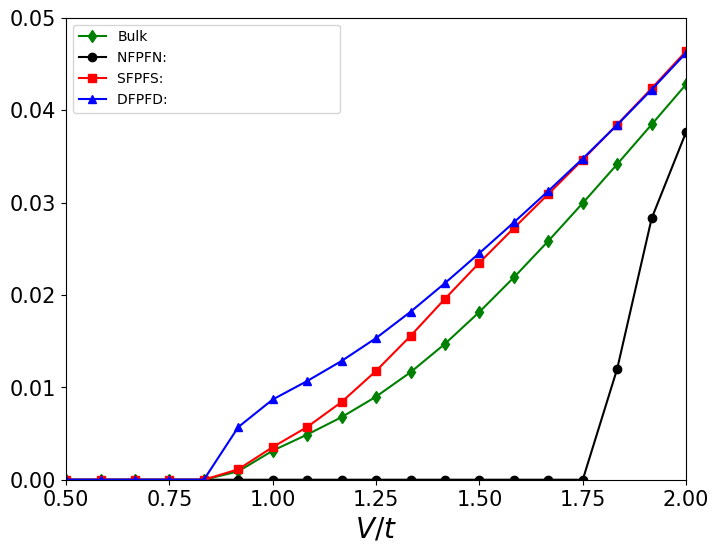

In [126]:
plt.figure(figsize=(8, 6))
plt.plot(V_prime_arr, bulk, '-d', label="Bulk", color='green')
plt.plot(V_prime_arr, nfpfn_arr, '-o', label="NFPFN:                                      ", color='black')
plt.plot(V_prime_arr, sfpfs_arr, '-s', label="SFPFS:                                      ", color='red')
plt.plot(V_prime_arr, dfpfd_arr, '-^', label="DFPFD:                                      ", color='blue')
plt.xlim(0.5, 2)
plt.ylim(0, 0.05)
plt.xticks(np.arange(0.5, 2.1, 0.25),fontsize=15)
plt.yticks(fontsize=15)
plt.xlabel(r"$V/t$", fontsize=20)
plt.legend()
plt.savefig("px_of_V_prime.svg")

In [90]:
print(V_prime_arr)

[1.7]


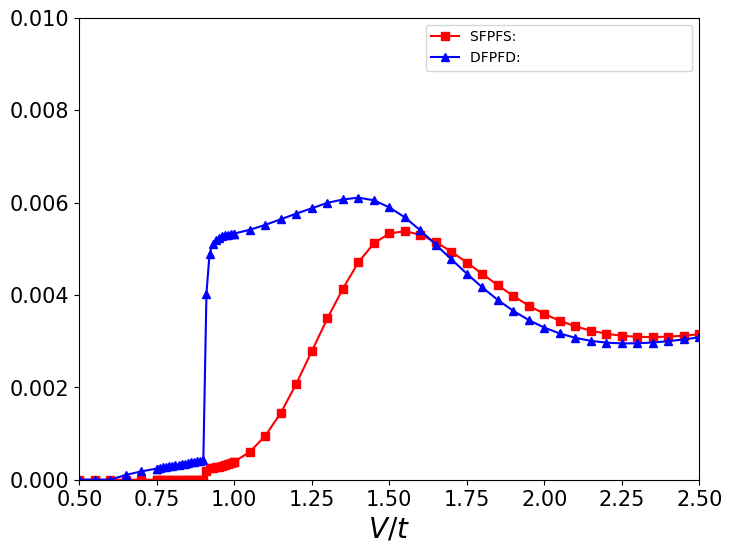

In [121]:
plt.figure(figsize=(8, 6))
plt.plot(V_prime_arr, sfpfs_arr-bulk, '-s', label="SFPFS:                                      ", color='red')
plt.plot(V_prime_arr, dfpfd_arr-bulk, '-^', label="DFPFD:                                      ", color='blue')
plt.xlim(0.5, 2.5)
plt.ylim(0, 0.01)
plt.xticks(np.arange(0.5, 2.51, 0.25),fontsize=15)
plt.yticks(fontsize=15)
plt.xlabel(r"$V/t$", fontsize=20)
plt.legend()
plt.savefig("px_of_V_prime.svg")

In [92]:
print("FINISHED!")

FINISHED!
